# Análise de Estratégias de Desconto: Fixo vs. Progressivo

**Objetivo:** comparar o faturamento estimado de uma campanha de e-commerce com desconto fixo e desconto progressivo, explicitando as premissas e limitações.

> Este notebook é uma simulação determinística baseada nos dados do estudo de caso. Os resultados não são previsões observadas nem comprovam causalidade. A distribuição horária dos usuários é uma hipótese que poderá ser substituída por dados históricos.

## Pergunta de negócio

**Os descontos progressivos aumentam o faturamento ou atraem mais clientes que gastam menos?**

## Cenários

- **Desconto fixo:** 15% durante as quatro horas.
- **Desconto progressivo:** 10%, 12%, 15% e 17%, por hora.
- Ticket médio original: R$ 350,00.
- Conversão média: 2%.
- Usuários esperados: 60.000 no cenário fixo e 80.000 no progressivo.


## 1. Importar bibliotecas

Usaremos Pandas para estruturar os cálculos, NumPy para operações numéricas e Matplotlib para os gráficos.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Definir as premissas

A distribuição de usuários por hora não foi fornecida no enunciado. Para começar de forma transparente:

- No cenário fixo, assumimos uma distribuição **uniforme**: 25% dos usuários em cada hora.
- No cenário progressivo, usamos a hipótese inicial de 10%, 20%, 30% e 40% dos usuários em cada hora.
- Mantemos a conversão em 2% em todos os períodos.

Essas distribuições são hipóteses de simulação, não resultados inferidos de dados históricos.

In [3]:
# Premissas gerais
ticket_original = 350.00
taxa_conversao = 0.02
duracao_horas = 4

usuarios_fixo_total = 60_000
usuarios_progressivo_total = 80_000

horarios = ["18h–19h", "19h–20h", "20h–21h", "21h–22h"]
desconto_fixo = 0.15
descontos_progressivos = np.array([0.10, 0.12, 0.15, 0.17])

# Hipóteses de distribuição dos usuários por hora
pesos_fixo = np.array([0.25, 0.25, 0.25, 0.25])
pesos_progressivo = np.array([0.10, 0.20, 0.30, 0.40])

assert np.isclose(pesos_fixo.sum(), 1.0)
assert np.isclose(pesos_progressivo.sum(), 1.0)

premissas = pd.DataFrame({
    "Premissa": [
        "Ticket médio original", "Taxa média de conversão",
        "Usuários esperados — desconto fixo",
        "Usuários esperados — desconto progressivo",
        "Desconto fixo", "Descontos progressivos"
    ],
    "Valor": [
        "R$ 350,00", "2%", f"{usuarios_fixo_total:,}",
        f"{usuarios_progressivo_total:,}", "15%", "10%, 12%, 15%, 17%"
    ]
})
display(premissas)


,Premissa,Valor
0,Ticket médio original,"R$ 350,00"
1,Taxa média de conversão,2%
2,Usuários esperados — desconto fixo,"60,000"
3,Usuários esperados — desconto progressivo,"80,000"
4,Desconto fixo,15%
5,Descontos progressivos,"10%, 12%, 15%, 17%"


## 3. Simular o cenário de desconto fixo

Fórmulas:

- `ticket_com_desconto = ticket_original × (1 − desconto)`
- `pedidos_esperados = usuários × taxa_de_conversão`
- `faturamento_estimado = pedidos_esperados × ticket_com_desconto`

Os pedidos são valores esperados; por isso, podem ser fracionários em outros cenários, embora aqui resultem em números inteiros.

In [4]:
usuarios_fixo_hora = usuarios_fixo_total * pesos_fixo
ticket_fixo = ticket_original * (1 - desconto_fixo)
pedidos_fixo = usuarios_fixo_hora * taxa_conversao
faturamento_fixo = pedidos_fixo * ticket_fixo

df_fixo = pd.DataFrame({
    "Horário": horarios,
    "Desconto": [desconto_fixo] * 4,
    "Usuários": usuarios_fixo_hora.astype(int),
    "Conversão": [taxa_conversao] * 4,
    "Pedidos esperados": pedidos_fixo,
    "Ticket médio (R$)": [ticket_fixo] * 4,
    "Faturamento estimado (R$)": faturamento_fixo
})

display(df_fixo)
print(f"Total de usuários: {df_fixo['Usuários'].sum():,.0f}")
print(f"Total de pedidos esperados: {df_fixo['Pedidos esperados'].sum():,.0f}")
print(f"Faturamento estimado: R$ {df_fixo['Faturamento estimado (R$)'].sum():,.2f}")


,Horário,Desconto,Usuários,Conversão,Pedidos esperados,Ticket médio (R$),Faturamento estimado (R$)
0,18h–19h,0.15,15000,0.02,300.00,297.50,"89,250.00"
1,19h–20h,0.15,15000,0.02,300.00,297.50,"89,250.00"
2,20h–21h,0.15,15000,0.02,300.00,297.50,"89,250.00"
3,21h–22h,0.15,15000,0.02,300.00,297.50,"89,250.00"


Total de usuários: 60,000
Total de pedidos esperados: 1,200
Faturamento estimado: R$ 357,000.00


## 4. Simular o cenário de desconto progressivo

A hipótese inicial distribui o público de forma crescente ao longo da campanha. O ticket médio é recalculado em cada hora, pois o desconto muda.

In [5]:
usuarios_prog_hora = usuarios_progressivo_total * pesos_progressivo
tickets_prog = ticket_original * (1 - descontos_progressivos)
pedidos_prog = usuarios_prog_hora * taxa_conversao
faturamento_prog = pedidos_prog * tickets_prog

df_progressivo = pd.DataFrame({
    "Horário": horarios,
    "Desconto": descontos_progressivos,
    "Usuários": usuarios_prog_hora.astype(int),
    "Conversão": [taxa_conversao] * 4,
    "Pedidos esperados": pedidos_prog,
    "Ticket médio (R$)": tickets_prog,
    "Faturamento estimado (R$)": faturamento_prog
})

display(df_progressivo)
print(f"Total de usuários: {df_progressivo['Usuários'].sum():,.0f}")
print(f"Total de pedidos esperados: {df_progressivo['Pedidos esperados'].sum():,.0f}")
print(f"Faturamento estimado: R$ {df_progressivo['Faturamento estimado (R$)'].sum():,.2f}")


,Horário,Desconto,Usuários,Conversão,Pedidos esperados,Ticket médio (R$),Faturamento estimado (R$)
0,18h–19h,0.10,8000,0.02,160.00,315.00,"50,400.00"
1,19h–20h,0.12,16000,0.02,320.00,308.00,"98,560.00"
2,20h–21h,0.15,24000,0.02,480.00,297.50,"142,800.00"
3,21h–22h,0.17,32000,0.02,640.00,290.50,"185,920.00"


Total de usuários: 80,000
Total de pedidos esperados: 1,600
Faturamento estimado: R$ 477,680.00


## 5. Comparar os cenários originais

A comparação abaixo usa os totais previstos no enunciado: 60.000 usuários para o desconto fixo e 80.000 para o progressivo. Portanto, a diferença observada mistura dois efeitos: o volume de público e o nível de desconto. Ela não isola o efeito causal da estratégia.

In [6]:
total_fixo = df_fixo["Faturamento estimado (R$)"].sum()
total_prog = df_progressivo["Faturamento estimado (R$)"].sum()

comparacao_original = pd.DataFrame({
    "Cenário": ["Desconto fixo", "Desconto progressivo"],
    "Usuários": [
        df_fixo["Usuários"].sum(),
        df_progressivo["Usuários"].sum()
    ],
    "Pedidos esperados": [
        df_fixo["Pedidos esperados"].sum(),
        df_progressivo["Pedidos esperados"].sum()
    ],
    "Faturamento estimado (R$)": [total_fixo, total_prog]
})
display(comparacao_original)

diferenca = total_prog - total_fixo
variacao_pct = (diferenca / total_fixo) * 100

print(f"Diferença estimada: R$ {diferenca:,.2f}")
print(f"Variação em relação ao cenário fixo: {variacao_pct:.2f}%")


,Cenário,Usuários,Pedidos esperados,Faturamento estimado (R$)
0,Desconto fixo,60000,"1,200.00","357,000.00"
1,Desconto progressivo,80000,"1,600.00","477,680.00"


Diferença estimada: R$ 120,680.00
Variação em relação ao cenário fixo: 33.80%


## 6. Gráficos da comparação original

Os gráficos ajudam a comparar o faturamento por hora e a composição dos cenários. As barras representam estimativas derivadas das premissas, não dados observados.

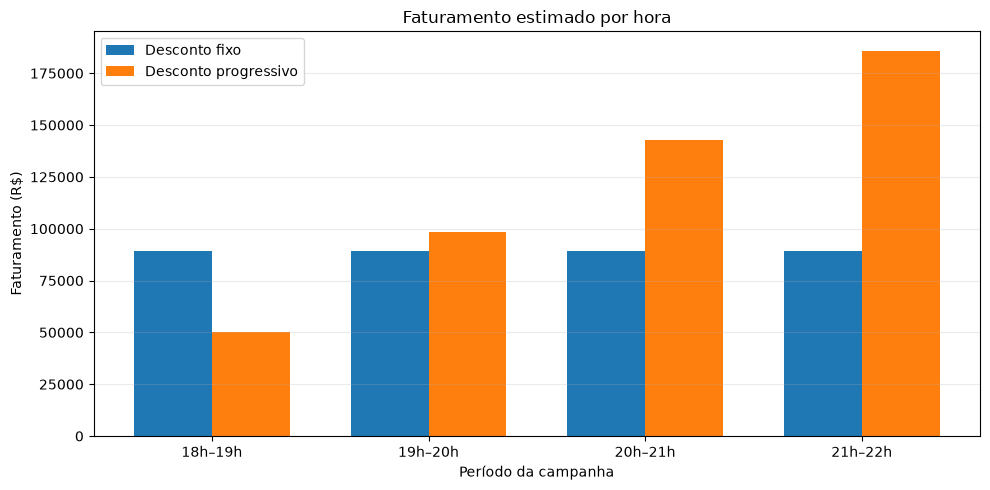

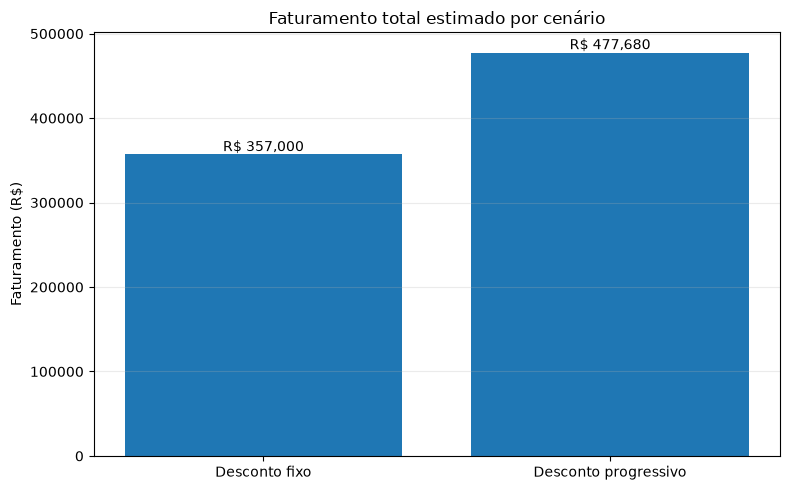

In [7]:
x = np.arange(len(horarios))
largura = 0.36

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - largura/2, df_fixo["Faturamento estimado (R$)"], largura, label="Desconto fixo")
ax.bar(x + largura/2, df_progressivo["Faturamento estimado (R$)"], largura, label="Desconto progressivo")
ax.set_title("Faturamento estimado por hora")
ax.set_xlabel("Período da campanha")
ax.set_ylabel("Faturamento (R$)")
ax.set_xticks(x, horarios)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
nomes = ["Desconto fixo", "Desconto progressivo"]
valores = [total_fixo, total_prog]
barras = ax.bar(nomes, valores)
ax.set_title("Faturamento total estimado por cenário")
ax.set_ylabel("Faturamento (R$)")
ax.grid(axis="y", alpha=0.25)
for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height(),
            f"R$ {valor:,.0f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


## 7. Comparação controlada: mesmo número de usuários

Para entender melhor o papel do desconto, repetimos o cenário progressivo com 60.000 usuários, mantendo os pesos horários de 10%, 20%, 30% e 40%. Isso iguala o total de usuários e a conversão entre os cenários.

Esta comparação ajuda a isolar o efeito aritmético dos descontos **dentro das hipóteses adotadas**, mas não mede como o desconto alteraria o comportamento real dos clientes.

In [8]:
usuarios_comuns = 60_000
usuarios_prog_controlado = usuarios_comuns * pesos_progressivo
pedidos_prog_controlado = usuarios_prog_controlado * taxa_conversao
faturamento_prog_controlado = pedidos_prog_controlado * tickets_prog

df_controlado = pd.DataFrame({
    "Horário": horarios,
    "Usuários": usuarios_prog_controlado.astype(int),
    "Desconto progressivo": descontos_progressivos,
    "Ticket médio (R$)": tickets_prog,
    "Pedidos esperados": pedidos_prog_controlado,
    "Faturamento progressivo (R$)": faturamento_prog_controlado
})
display(df_controlado)

total_prog_controlado = df_controlado["Faturamento progressivo (R$)"].sum()
diferenca_controlada = total_prog_controlado - total_fixo
variacao_controlada = diferenca_controlada / total_fixo * 100

resumo_controlado = pd.DataFrame({
    "Cenário": ["Desconto fixo (15%)", "Progressivo — mesmo público"],
    "Usuários": [usuarios_comuns, usuarios_comuns],
    "Pedidos esperados": [usuarios_comuns * taxa_conversao,
                           usuarios_comuns * taxa_conversao],
    "Faturamento estimado (R$)": [total_fixo, total_prog_controlado]
})
display(resumo_controlado)

print(f"Diferença: R$ {diferenca_controlada:,.2f}")
print(f"Variação percentual: {variacao_controlada:.2f}%")


,Horário,Usuários,Desconto progressivo,Ticket médio (R$),Pedidos esperados,Faturamento progressivo (R$)
0,18h–19h,6000,0.10,315.00,120.00,"37,800.00"
1,19h–20h,12000,0.12,308.00,240.00,"73,920.00"
2,20h–21h,18000,0.15,297.50,360.00,"107,100.00"
3,21h–22h,24000,0.17,290.50,480.00,"139,440.00"


,Cenário,Usuários,Pedidos esperados,Faturamento estimado (R$)
0,Desconto fixo (15%),60000,"1,200.00","357,000.00"
1,Progressivo — mesmo público,60000,"1,200.00","358,260.00"


Diferença: R$ 1,260.00
Variação percentual: 0.35%


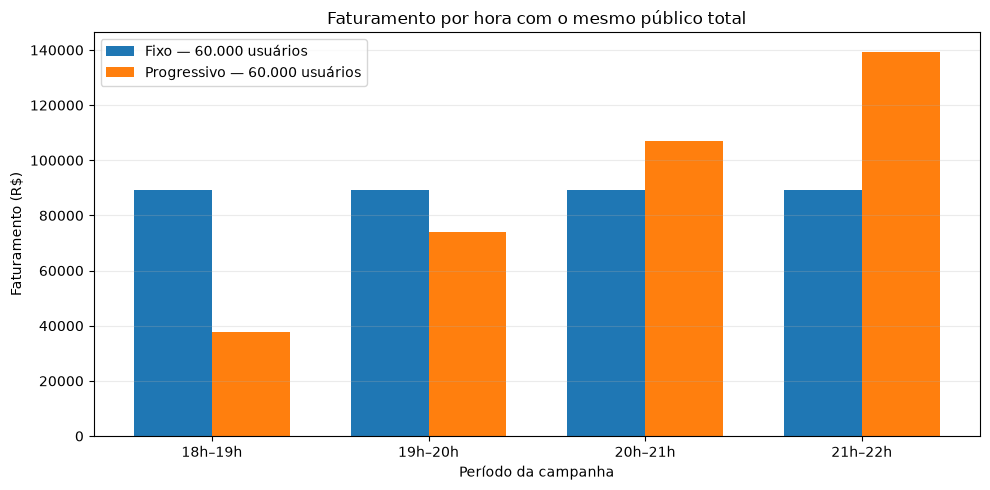

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - largura/2, df_fixo["Faturamento estimado (R$)"], largura, label="Fixo — 60.000 usuários")
ax.bar(x + largura/2, df_controlado["Faturamento progressivo (R$)"], largura, label="Progressivo — 60.000 usuários")
ax.set_title("Faturamento por hora com o mesmo público total")
ax.set_xlabel("Período da campanha")
ax.set_ylabel("Faturamento (R$)")
ax.set_xticks(x, horarios)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Análise de sensibilidade: e se a conversão mudar?

Até agora, usamos conversão constante de 2%. Na prática, a conversão pode variar por horário e estratégia. A análise de sensibilidade abaixo mostra como o faturamento estimado muda quando a taxa de conversão do cenário progressivo varia, mantendo os 80.000 usuários e a distribuição horária assumida.

Esta análise **não prevê** a conversão real; ela mostra cenários hipotéticos.

,Taxa de conversão,Pedidos esperados,Faturamento estimado (R$)
0,0.01,800.00,"238,840.00"
1,0.01,"1,200.00","358,260.00"
2,0.02,"1,600.00","477,680.00"
3,0.03,"2,000.00","597,100.00"
4,0.03,"2,400.00","716,520.00"


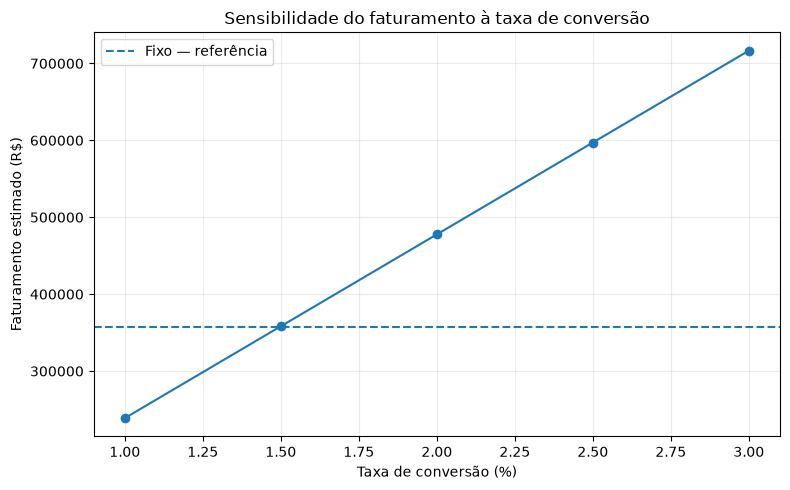

In [ ]:
taxas = np.array([0.01, 0.015, 0.02, 0.025, 0.03])
sensibilidade = []

for taxa in taxas:
    pedidos = usuarios_prog_hora * taxa
    receita = np.sum(pedidos * tickets_prog)
    sensibilidade.append({
        "Taxa de conversão": taxa,
        "Pedidos esperados": pedidos.sum(),
        "Faturamento estimado (R$)": receita
    })

df_sensibilidade = pd.DataFrame(sensibilidade)
display(df_sensibilidade)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_sensibilidade["Taxa de conversão"] * 100,
        df_sensibilidade["Faturamento estimado (R$)"],
        marker="o")
ax.axhline(total_fixo, linestyle="--", label="Fixo — referência")
ax.set_title("Sensibilidade do faturamento à taxa de conversão")
ax.set_xlabel("Taxa de conversão (%)")
ax.set_ylabel("Faturamento estimado (R$)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Conclusões

Com as premissas iniciais:

- O cenário fixo estima faturamento de **R$ 357.000,00**.
- O cenário progressivo com 80.000 usuários estima faturamento de **R$ 477.680,00**.
- A diferença de **R$ 120.680,00 (+33,8%)** ocorre em um cenário que também pressupõe mais usuários para a estratégia progressiva.
- Ao igualar os dois cenários em 60.000 usuários, o faturamento progressivo estimado é de **R$ 358.260,00**, apenas **R$ 1.260,00 (+0,35%)** acima do fixo.

**Interpretação:** sob as hipóteses adotadas, a maior parte da diferença do cenário original está associada ao volume maior de usuários presumido para o desconto progressivo. Não é possível concluir que a estratégia progressiva causará esse aumento sem dados históricos ou um experimento controlado.

## 10. Limitações e próximos passos

- A distribuição de usuários por hora é hipotética.
- A taxa de conversão foi mantida constante em todos os períodos.
- O ticket médio foi ajustado proporcionalmente ao desconto, sem modelar mix de produtos ou margem.
- Não foram incluídos custos, estoque, cancelamentos, devoluções ou lucro.
- A simulação é determinística e não calcula intervalos de confiança.

Próximos passos:
1. Substituir as hipóteses horárias por dados históricos, se disponíveis.
2. Avaliar distribuições adequadas para contagens de chegadas e taxas de conversão.
3. Simular incerteza e intervalos de resultados.
4. Comparar margem ou lucro, além do faturamento.
5. Se possível, validar as estratégias por meio de um teste A/B.

## Tecnologias

- Python
- Pandas
- NumPy
- Matplotlib

---

*Projeto desenvolvido como exercício de aprendizado em probabilidade, análise de cenários e tomada de decisão orientada por dados.*
